# 05 · Why complementary RCT covariates may not identify joint CATE

**Question:** if one randomized trial measures `X1` and another measures `X2`, does their combination identify the effect conditional on both variables?

Not in general. We will enumerate two complete data-generating worlds. Every observable distribution in both trials is identical, but their joint CATEs have opposite signs. This is a finite mathematical example, not a performance experiment or an implemented multi-source benchmark API. The current benchmark interface remains one OBS plus one RCT.

Install `python -m pip install -e '.[baselines,notebooks]'` before running. This notebook needs only NumPy, Matplotlib and IPython; it downloads no data.


In [1]:
%matplotlib inline
from collections import Counter
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({'figure.dpi': 105, 'font.size': 10})


## Two worlds from the same covariate law

Let `X1` and `X2` be independent uniform signs in `{-1,+1}`. In both trials, `T` is randomized independently with probability one half. Define `Y(0)=0` and `Y(1)=theta*X1*X2`, where the unknown world index is `theta=+1` or `theta=-1`.

Each trial samples this same population. Trial 1 records `(X1,T,Y)`; trial 2 records `(X2,T,Y)`. Individuals are not linked across trials. Even knowing the target joint covariate distribution does not distinguish the worlds. We use all eight equally probable complete `(X1,X2,T)` states, so there is no simulation error.


In [2]:
states = tuple(product((-1, 1), (-1, 1), (0, 1)))
assert len(states) == 8

def complete_world(theta):
    return [(x1, x2, t, t * theta * x1 * x2) for x1, x2, t in states]

def observed_counts(theta, trial):
    coordinate = trial - 1
    return Counter((row[coordinate], row[2], row[3]) for row in complete_world(theta))

observed = {(theta, trial): observed_counts(theta, trial)
            for theta in (-1, 1) for trial in (1, 2)}
assert observed[-1, 1] == observed[1, 1]
assert observed[-1, 2] == observed[1, 2]
print('Exact observable equality holds in each trial; every count has denominator 8.')


Exact observable equality holds in each trial; every count has denominator 8.


## Check the entire observable distribution

Checking marginal effects alone would be insufficient. The next table compares every `(observed X,T,Y)` outcome for each trial. Their joint distributions coincide, including outcomes, treatment and the recorded covariate.


In [3]:
for trial in (1, 2):
    left, right = observed[-1, trial], observed[1, trial]
    lines = [f'| {x} | {t} | {y} | {left[x,t,y]}/8 | {right[x,t,y]}/8 |'
             for x, t, y in sorted(set(left) | set(right))]
    display(Markdown(f'### Trial {trial}: records X{trial}\n\n'
        '| Observed X | T | Y | theta=-1 | theta=+1 |\n|---:|---:|---:|---:|---:|\n'
        + '\n'.join(lines)))


### Trial 1: records X1

| Observed X | T | Y | theta=-1 | theta=+1 |
|---:|---:|---:|---:|---:|
| -1 | 0 | 0 | 2/8 | 2/8 |
| -1 | 1 | -1 | 1/8 | 1/8 |
| -1 | 1 | 1 | 1/8 | 1/8 |
| 1 | 0 | 0 | 2/8 | 2/8 |
| 1 | 1 | -1 | 1/8 | 1/8 |
| 1 | 1 | 1 | 1/8 | 1/8 |

### Trial 2: records X2

| Observed X | T | Y | theta=-1 | theta=+1 |
|---:|---:|---:|---:|---:|
| -1 | 0 | 0 | 2/8 | 2/8 |
| -1 | 1 | -1 | 1/8 | 1/8 |
| -1 | 1 | 1 | 1/8 | 1/8 |
| 1 | 0 | 0 | 2/8 | 2/8 |
| 1 | 1 | -1 | 1/8 | 1/8 |
| 1 | 1 | 1 | 1/8 | 1/8 |

## The desired joint CATE still differs

The target is `tau_theta(x1,x2)=theta*x1*x2`. In either world the average effect and effects conditional on only `X1` or only `X2` are zero. Those projected effects do not determine the interaction.


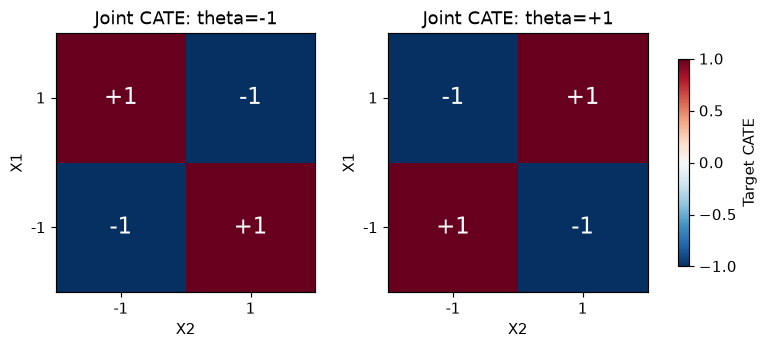

In [4]:
points = np.array(list(product((-1, 1), repeat=2)))
tau = {theta: theta * points[:, 0] * points[:, 1] for theta in (-1, 1)}
for theta in (-1, 1):
    assert tau[theta].mean() == 0
    for column in (0, 1):
        for value in (-1, 1):
            assert tau[theta][points[:, column] == value].mean() == 0

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2), constrained_layout=True)
for ax, theta in zip(axes, (-1, 1)):
    matrix = tau[theta].reshape(2, 2)
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap='RdBu_r', origin='lower')
    for i, j in product(range(2), repeat=2):
        ax.text(j, i, f'{matrix[i,j]:+d}', ha='center', va='center', color='white', fontsize=16)
    ax.set(xticks=[0, 1], xticklabels=[-1, 1], yticks=[0, 1], yticklabels=[-1, 1],
           xlabel='X2', ylabel='X1', title=f'Joint CATE: theta={theta:+d}')
fig.colorbar(image, ax=axes, label='Target CATE', shrink=0.8)
plt.show()


## Why a point-estimation ranking would miss the issue

Take any predicted joint effect vector `f`. With equal mass on the four target covariate states, the average squared error across the two indistinguishable worlds is

`(MSE(f,tau_+) + MSE(f,tau_-))/2 = mean(f**2) + 1 >= 1`.

Therefore at least one of the two risks is at least one. This is an identification obstruction even with unlimited trial samples; it is not a small-sample or optimizer failure. The equality follows by expanding the two squares, not from a fitted benchmark scorer.


In [5]:
f = np.array([0.25, -0.4, 0.7, 0.1])  # Any fixed prediction, not fitted to truth.
risk = {theta: np.mean((f - tau[theta]) ** 2) for theta in (-1, 1)}
np.testing.assert_allclose(np.mean(list(risk.values())), np.mean(f ** 2) + 1)
print({'MSE_world_minus': round(risk[-1], 4), 'MSE_world_plus': round(risk[1], 4),
       'average_risk_lower_bound': 1.0})


{'MSE_world_minus': 1.2056, 'MSE_world_plus': 1.1556, 'average_risk_lower_bound': 1.0}


## What extra information distinguishes these particular worlds?

A validation trial that jointly observes `(X1,X2,T,Y)` would distinguish them. Merely observing unlabeled target `(X1,X2)` would not, since that covariate law is identical. One could instead impose a justified outcome structure excluding this interaction, but that changes the model class and rules out the example rather than learning the interaction from the original data.


In [6]:
linked_minus = Counter(complete_world(-1))
linked_plus = Counter(complete_world(1))
assert linked_minus != linked_plus
print('Jointly measured trial distributions differ:', linked_minus != linked_plus)


Jointly measured trial distributions differ: True


## Implications for a multi-source benchmark

A future interface should declare each source's observed variables, treatment assignment, population/support and potential-outcome law, plus the target's conditioning set. It should distinguish identification under stated assumptions, partial identification, and estimation error once identification holds. Adding masks alone does not establish that a point-CATE target is identified.

Relevant primary precedents cover different pieces of this problem:

- [Hussain et al., Falsification before Extrapolation (NeurIPS 2022)](https://proceedings.neurips.cc/paper_files/paper/2022/hash/28b5dfc51e5ae12d84fb7c6172a00df4-Abstract-Conference.html): one RCT and multiple OBS sources; group-effect confidence sets require at least one valid OBS estimator.
- [Li et al., Robust Direct Learning (PMLR 2023)](https://proceedings.mlr.press/v189/li23c.html): source-specific adjustment variables, with within-source unconfoundedness.
- [Steingrimsson et al., Systematically missing data in causally interpretable meta-analysis (2024)](https://arxiv.org/abs/2205.00610): transported average effects from trials with different missing-covariate patterns under stated transport assumptions.

This counterexample is an elementary construction for the tutorial; it is not a novelty claim about identification theory. See [coverage](../docs/COVERAGE.md) for the implemented interface and [the tutorial guide](README.md) for the other notebooks.
